In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [4]:
df = pd.read_csv("sales_dataset.csv")

df.head()

,Week,Advertising_Spend_INR_X,Sales_Units_Y
0,2025-01-06,9016,601
1,2025-01-13,39828,813
2,2025-01-20,34456,238
3,2025-01-27,24749,751
4,2025-02-03,24486,274


In [5]:
print(df.isnull().sum())

Week                       0
Advertising_Spend_INR_X    0
Sales_Units_Y              0
dtype: int64


In [7]:
df = df.dropna()

In [8]:
X = df[['Advertising_Spend_INR_X']]

Y = df['Sales_Units_Y']

print(X.head())
print(Y.head())

   Advertising_Spend_INR_X
0                     9016
1                    39828
2                    34456
3                    24749
4                    24486
0    601
1    813
2    238
3    751
4    274
Name: Sales_Units_Y, dtype: int64


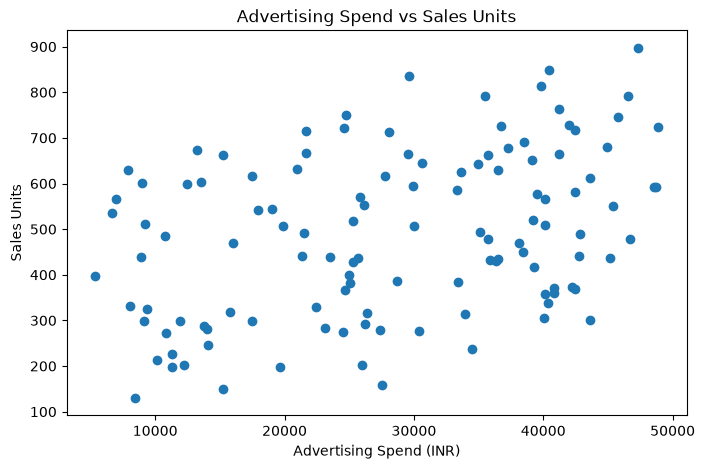

In [9]:
plt.figure(figsize=(8,5))

plt.scatter(X, Y)

plt.xlabel("Advertising Spend (INR)")
plt.ylabel("Sales Units")

plt.title("Advertising Spend vs Sales Units")

plt.show()

In [10]:
correlation = df[
    ['Advertising_Spend_INR_X', 'Sales_Units_Y']
].corr()

print(correlation)

                         Advertising_Spend_INR_X  Sales_Units_Y
Advertising_Spend_INR_X                 1.000000       0.375458
Sales_Units_Y                           0.375458       1.000000


In [11]:
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.20,
    random_state=10
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (96, 1)
Testing data: (24, 1)


In [12]:
model = LinearRegression()

model.fit(X_train, Y_train)

print("Model training completed")

Model training completed


In [13]:
print("Intercept:", model.intercept_)

print("Coefficient:", model.coef_[0])

Intercept: 356.8122672816384
Coefficient: 0.004723507928863168


In [14]:
a = model.intercept_
b = model.coef_[0]

print("Regression Equation:")
print(f"Sales = {a:.2f} + {b:.4f} × Advertising Spend")

Regression Equation:
Sales = 356.81 + 0.0047 × Advertising Spend


In [15]:
Y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Sales': Y_test,
    'Predicted Sales': Y_pred
})

print(result.head(10))

     Actual Sales  Predicted Sales
45            593       586.762080
79            494       522.805783
56            836       496.609208
85            629       529.276989
99            227       410.135948
41            651       541.567556
81            367       473.350655
110           616       439.331951
48            791       524.529863
2             238       519.565456


In [16]:
r2 = r2_score(Y_test, Y_pred)

print("R2 Score:", r2)

R2 Score: 0.17883579944166328


In [17]:
mae = mean_absolute_error(Y_test, Y_pred)

print("MAE:", mae)

MAE: 168.32640592443917


In [18]:
mse = mean_squared_error(Y_test, Y_pred)

print("MSE:", mse)

MSE: 38095.83736428595


In [19]:
rmse = np.sqrt(mse)

print("RMSE:", rmse)

RMSE: 195.18154975377655


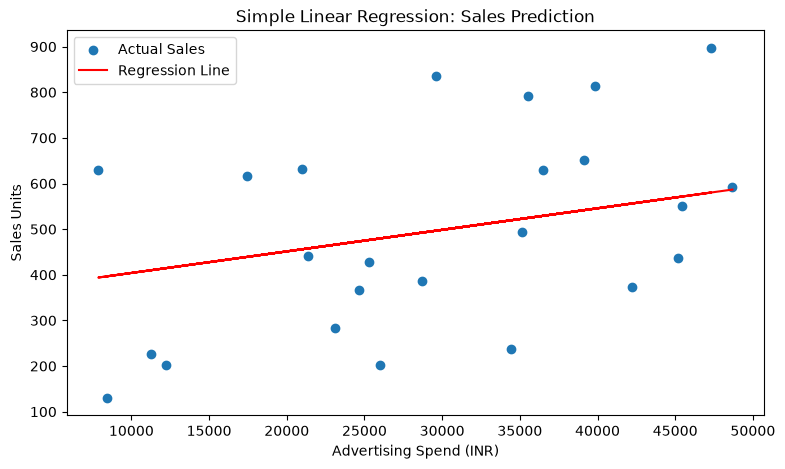

In [20]:
plt.figure(figsize=(9,5))

plt.scatter(X_test, Y_test, label="Actual Sales")

plt.plot(
    X_test.iloc[:, 0],
    Y_pred,
    color="red",
    label="Regression Line"
)

plt.xlabel("Advertising Spend (INR)")
plt.ylabel("Sales Units")

plt.title("Simple Linear Regression: Sales Prediction")

plt.legend()
plt.show()

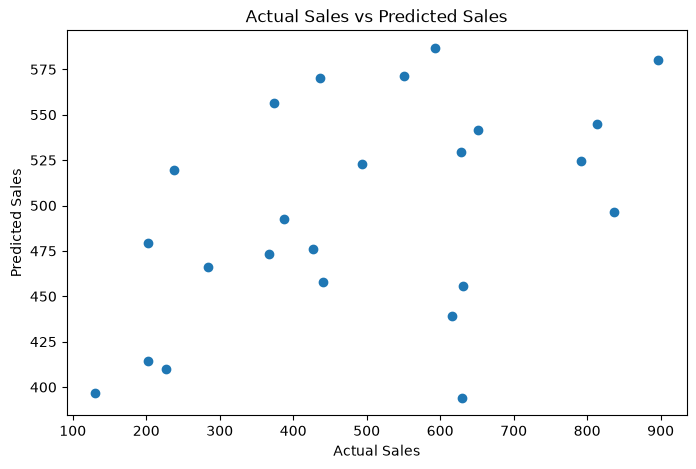

In [21]:
plt.figure(figsize=(8,5))

plt.scatter(Y_test, Y_pred)

plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")

plt.title("Actual Sales vs Predicted Sales")

plt.show()

In [22]:
new_advertising = pd.DataFrame({
    'Advertising_Spend_INR_X': [30000]
})

predicted_sales = model.predict(new_advertising)

print("Advertising Spend: Rs. 30,000")

print("Expected Sales Units:",
      round(predicted_sales[0]))

Advertising Spend: Rs. 30,000
Expected Sales Units: 499


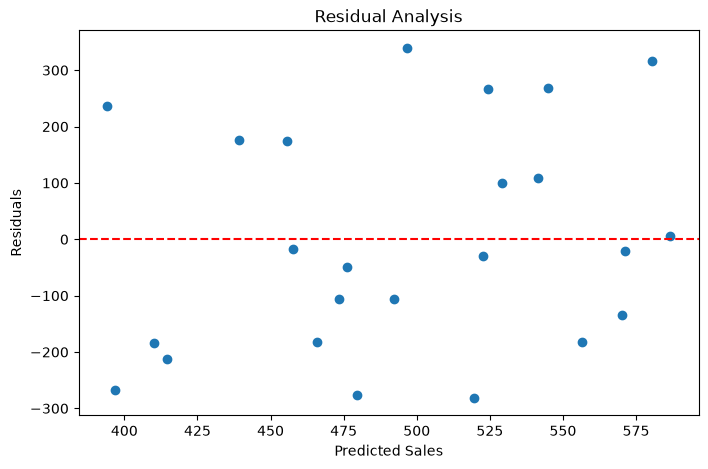

In [23]:
residuals = Y_test - Y_pred

plt.figure(figsize=(8,5))

plt.scatter(Y_pred, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals")

plt.title("Residual Analysis")

plt.show()